 Importation des bibliothèques

In [3]:
import sklearn
print(sklearn.__version__)

1.9.1


In [4]:
from pathlib import Path
import pickle

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import Lasso, LinearRegression
from sklearn.metrics import root_mean_squared_error
from xgboost import XGBRegressor

pandas lit et prépare les données. DictVectorizer transforme les variables en matrice numérique. Les deux modèles serviront à comparer deux entraînements.

Localisation du fichier Parquet

In [5]:
data_path = Path("data/yellow_tripdata_2026-05.parquet")

if not data_path.exists():
    raise FileNotFoundError(f"Fichier introuvable : {data_path}")

data_path

PosixPath('data/yellow_tripdata_2026-05.parquet')

Lecture de données
(Avec df.shape pour voir le nmbre de lignes et de colonnes et le df.head() pour afficher les 5 premières lignes)

In [6]:
df = pd.read_parquet(data_path, columns=["tpep_pickup_datetime", "tpep_dropoff_datetime", "PULocationID", "DOLocationID", "trip_distance"])

#df = pd.read_parquet(data_path)
df.shape
#df.head()

(4090836, 5)

Affichage des colonnes utiles 

In [7]:
columns = [
    "tpep_pickup_datetime",
    "tpep_dropoff_datetime",
    "PULocationID",
    "DOLocationID",
    "trip_distance",
]

df[columns].head()

,tpep_pickup_datetime,tpep_dropoff_datetime,PULocationID,DOLocationID,trip_distance
0,2026-05-01 00:04:59,2026-05-01 00:32:48,138,37,7.51
1,2026-05-01 00:37:05,2026-05-01 00:59:47,138,237,6.14
2,2026-05-01 00:34:05,2026-05-01 00:54:02,249,232,2.40
3,2026-05-01 00:55:07,2026-05-01 01:02:43,232,114,1.20
4,2026-05-01 00:44:13,2026-05-01 00:44:13,140,237,0.86


Visualisation rapide

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

# Copie légère avec la durée en minutes
trips = df[columns].copy()
trips["duration"] = (
    trips["tpep_dropoff_datetime"] - trips["tpep_pickup_datetime"]
).dt.total_seconds() / 60

print(trips["duration"].describe())

count    200000.000000
mean         17.105222
std          11.250166
min           1.000000
25%           8.800000
50%          14.383333
75%          22.483333
max          60.000000
Name: duration, dtype: float64


Distribution de la durée

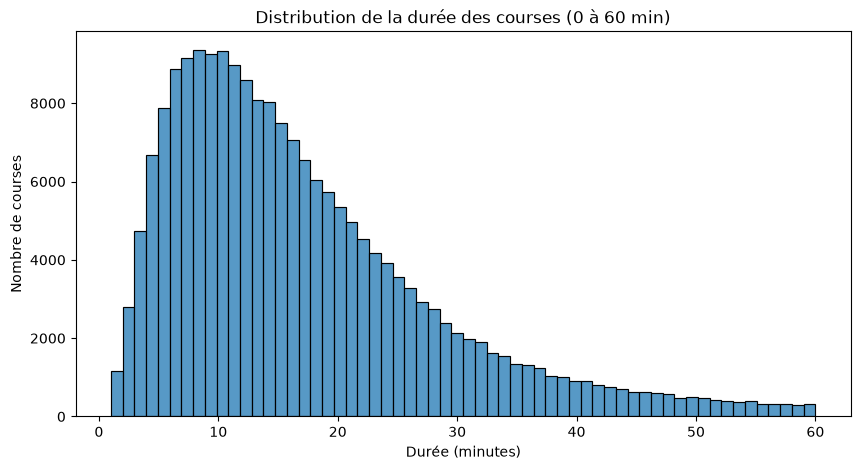

In [27]:
# On garde les durées plausibles pour que le graphe soit lisible
plot_df = trips[(trips["duration"] >= 0) & (trips["duration"] <= 60)]

plt.figure(figsize=(10, 5))
sns.histplot(plot_df["duration"], bins=60)
plt.title("Distribution de la durée des courses (0 à 60 min)")
plt.xlabel("Durée (minutes)")
plt.ylabel("Nombre de courses")
plt.show()

Le pic se situe autour de 8 à 11 minutes. C'est la durée la plus fréquente d'une course en taxi jaune, ce qui correspond à des trajets courts en ville.
La forme est asymétrique : montée rapide jusqu'au pic, puis décroissance lente vers la droite (longue queue). La moyenne sera donc supérieure au mode, tirée vers le haut par les longues courses.
Peu de courses sous 3 minutes, et aucune barre avant environ 1 minute. Cela suggère que les durées très courtes ont déjà été retirées, ou qu'elles sont rares.
Au-delà de 40 minutes, les effectifs deviennent faibles mais ne tombent pas à zéro. Le graphe s'arrête à 60 minutes : ce qu'il y a après (courses très longues, erreurs) n'est pas visible ici.

Distance en fonction de la durée

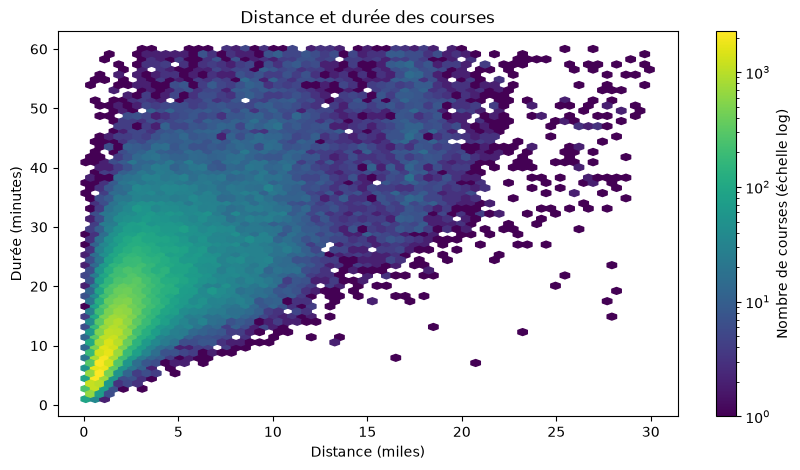

In [28]:
# Échantillon pour ne pas saturer la mémoire ni le graphe
sample = trips[
    (trips["duration"].between(1, 60)) & (trips["trip_distance"].between(0.1, 30))
].sample(100_000, random_state=42)

plt.figure(figsize=(10, 5))
plt.hexbin(sample["trip_distance"], sample["duration"], gridsize=60, bins="log", cmap="viridis")
plt.colorbar(label="Nombre de courses (échelle log)")
plt.title("Distance et durée des courses")
plt.xlabel("Distance (miles)")
plt.ylabel("Durée (minutes)")
plt.show()

Zone la plus dense (jaune) : courses de 0 à 3 miles et de 5 à 20 minutes. Les échelles de couleur sont logarithmiques : le centre compte plusieurs milliers de courses par cellule, les bords seulement une ou quelques-unes.
Relation positive : plus la distance augmente, plus la durée augmente. Le nuage monte vers la droite.
Une frontière basse nette : pour une distance donnée, il existe une durée minimale en dessous de laquelle presque aucune course n'apparaît. Cette frontière correspond à la vitesse maximale réaliste d'un taxi.
Forte dispersion vers le haut : à distance égale, la durée varie beaucoup. Une course de 2 miles peut durer 10 minutes comme 50. Cela reflète le trafic, les arrêts, l'heure de la journée, ou des courses où le taxi a attendu.
Quelques points isolés suspects en bas à droite (par exemple environ 16 miles en 8 minutes, ou 20 miles en 7 minutes) : cela donnerait des vitesses irréalistes, donc très probablement des erreurs de saisie ou de capteur.

Calcul de la durée

In [8]:
df["duration"] = (
    df["tpep_dropoff_datetime"] - df["tpep_pickup_datetime"]
).dt.total_seconds() / 60

df["duration"].describe()

count    4.090836e+06
mean     1.877588e+01
std      2.671057e+01
min      0.000000e+00
25%      8.583333e+00
50%      1.448333e+01
75%      2.326667e+01
max      9.960150e+03
Name: duration, dtype: float64

Filtrer et préparer les variables

In [9]:
df = df[df["duration"].between(1, 60)].copy()

categorical = ["PULocationID", "DOLocationID"]
numerical = ["trip_distance"]

df[categorical] = df[categorical].astype(str)
df["PU_DO"] = df["PULocationID"] + "_" + df["DOLocationID"]

df.shape

(3883752, 7)

In [ ]:
sample_size = min(200_000, len(df))
df = df.sample(n=sample_size, random_state=42)
df = df.sort_values("tpep_pickup_datetime").reset_index(drop=True)

Séparer entraînement et validation

In [12]:
split_index = int(len(df) * 0.8)

df_train = df.iloc[:split_index].copy()
df_val = df.iloc[split_index:].copy()

len(df_train), len(df_val)

(160000, 40000)

Transformer les variables

In [13]:
features = ["PU_DO", "trip_distance"]

train_dicts = df_train[features].to_dict(orient="records")
val_dicts = df_val[features].to_dict(orient="records")

dv = DictVectorizer()
X_train = dv.fit_transform(train_dicts)
X_val = dv.transform(val_dicts)

y_train = df_train["duration"].to_numpy()
y_val = df_val["duration"].to_numpy()

X_train.shape, X_val.shape

((160000, 12641), (40000, 12641))

Entraîner la régression linéaire

In [14]:
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

linear_predictions = linear_model.predict(X_val)
linear_rmse = root_mean_squared_error(y_val, linear_predictions)

linear_rmse

6.652815344851184

La RMSE mesure l'écart entre les durées prédites et les durées réelles. Elle est exprimée en minutes. Une valeur plus faible indique une erreur moyenne mieux maîtrisée, avec une pénalisation plus forte des grandes erreurs.

Comparer les distributions

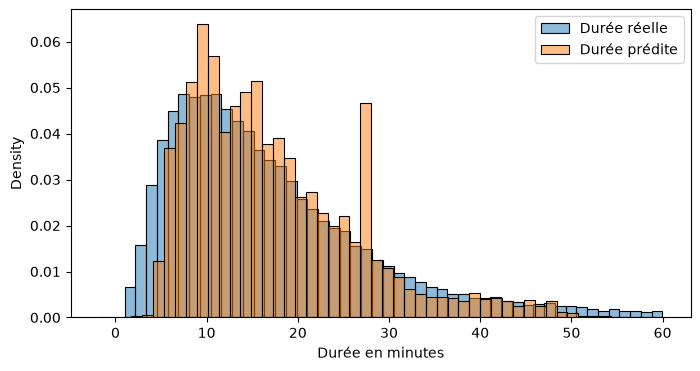

In [15]:
plt.figure(figsize=(8, 4))
sns.histplot(y_val, label="Durée réelle", stat="density", bins=50, alpha=0.5)
sns.histplot(
    linear_predictions,
    label="Durée prédite",
    stat="density",
    bins=50,
    alpha=0.5,
)
plt.xlabel("Durée en minutes")
plt.legend()
# plt.show()

Entraîner un modèle Lasso

In [21]:
import numpy as np

def to_int32_indices(X):
    X = X.tocsr()
    assert X.nnz < np.iinfo(np.int32).max, "Matrice trop grande pour des indices int32"
    X.indices = X.indices.astype(np.int32)
    X.indptr = X.indptr.astype(np.int32)
    return X

X_train = to_int32_indices(X_train)
X_val = to_int32_indices(X_val)

In [22]:
lasso_model = Lasso(alpha=0.01, max_iter=10_000)
lasso_model.fit(X_train, y_train)

lasso_predictions = lasso_model.predict(X_val)
lasso_rmse = root_mean_squared_error(y_val, lasso_predictions)

lasso_rmse

10.517043400486218

Exercice : entraîner un modèle XGBoost

XGBoost construit successivement plusieurs arbres de décision. Chaque nouvel arbre cherche à corriger une partie des erreurs commises par les arbres précédents. Le modèle peut apprendre des relations non linéaires, mais son entraînement demande davantage de ressources et de paramètres à contrôler.

In [17]:
xgb_model = XGBRegressor(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1,
)

xgb_model.fit(X_train, y_train)

xgb_predictions = xgb_model.predict(X_val)
xgb_rmse = root_mean_squared_error(y_val, xgb_predictions)

xgb_rmse

6.471618951707119

In [23]:
results = pd.DataFrame(
    {
        "model": ["LinearRegression", "Lasso", "XGBoost"],
        "rmse": [linear_rmse, lasso_rmse, xgb_rmse],
    }
).sort_values("rmse")

results

,model,rmse
2,XGBoost,6.471619
0,LinearRegression,6.652815
1,Lasso,10.517043


Ici, on retiendra le modèle XGBoost.

Sauvegarder le modèle retenu

In [24]:
models = {
    "LinearRegression": (linear_model, linear_rmse),
    "Lasso": (lasso_model, lasso_rmse),
    "XGBoost": (xgb_model, xgb_rmse),
}

selected_name = min(models, key=lambda name: models[name][1])
selected_model, selected_rmse = models[selected_name]

models_dir = Path("models")
models_dir.mkdir(exist_ok=True)
model_path = models_dir / "duration_model.bin"

with model_path.open("wb") as output_file:
    pickle.dump((dv, selected_model), output_file)

selected_name, selected_rmse, model_path

('XGBoost', 6.471618951707119, PosixPath('models/duration_model.bin'))

Vérifier le fichier sauvegardé

In [25]:
with model_path.open("rb") as input_file:
    loaded_dv, loaded_model = pickle.load(input_file)

example = [{"PU_DO": "161_236", "trip_distance": 3.2}]
example_matrix = loaded_dv.transform(example)
prediction = loaded_model.predict(example_matrix)[0]

prediction

np.float32(21.65231)

dictionnaire permettant de stocker le résultat des essais

In [29]:
results = {}
results["lasso_alpha_0.01"] = lasso_rmse

lasso avec 0.001

In [ ]:
lasso_model_1 = Lasso(alpha=0.001, max_iter=10_000)
lasso_model_1.fit(X_train, y_train) #entrainement

lasso_predictions_1 = lasso_model_1.predict(X_val) #prédiction
lasso_rmse_1 = root_mean_squared_error(y_val, lasso_predictions_1) #calcul ddu taux d'erreur

results["lasso_alpha_0.001"] = lasso_rmse_1 #stockage dans results
lasso_rmse_1

7.877294379084631

LASSO avec 0.1

In [31]:
lasso_model_2 = Lasso(alpha=0.1, max_iter=10_000)
lasso_model_2.fit(X_train, y_train)

lasso_predictions_2 = lasso_model_2.predict(X_val)
lasso_rmse_2 = root_mean_squared_error(y_val, lasso_predictions_2)

results["lasso_alpha_0.1"] = lasso_rmse_2
lasso_rmse_2

10.97771869202461

XGBoost avec paramètre modifiée

In [32]:
xgb_model = XGBRegressor(
    max_depth=4,          # paramètre modifié (valeur par défaut : 6)
    random_state=42,
)
xgb_model.fit(X_train, y_train)

xgb_predictions = xgb_model.predict(X_val)
xgb_rmse = root_mean_squared_error(y_val, xgb_predictions)

results["xgboost_max_depth_4"] = xgb_rmse
xgb_rmse

6.443464642537762

Récupérons les taux d'erreurs de chaque essai

In [33]:
for name, rmse in results.items():
    print(f"{name:25s} RMSE validation : {rmse:.4f}")

lasso_alpha_0.01          RMSE validation : 10.5170
lasso_alpha_0.001         RMSE validation : 7.8773
lasso_alpha_0.1           RMSE validation : 10.9777
xgboost_max_depth_4       RMSE validation : 6.4435


Ici le modèle retenu est celui avec pour RMSE = 6.4435